
# SVM Baseline for Malware Detection

## Objectives

The objective of this notebook is to develop a Support Vector Machine (SVM) baseline model for malware detection using the preprocessed BODMAS dataset.

The model classifies Windows executable files into two categories:
- 0: Benign
- 1: Malicious

The main objectives are:
- Load and validate the dataset.
- Analyze the distribution of the target classes.
- Apply feature selection to reduce dimensionality.
- Build an SVM classification model.
- Optimize the model hyperparameters using cross-validation.
- Evaluate the model using classification metrics.
- Save the trained model for future adversarial experiments.


## 1. Data Integration

### 1.1 Loading the Preprocessed Dataset

The preprocessed BODMAS dataset is loaded from the processed-data directory. Data preprocessing and the train/test split have already been performed in an earlier stage of the project.

Each sample is represented by 2,381 numerical features. The dataset is provided in four arrays:

- `X_train` and `y_train`: features and labels used for model training and hyperparameter tuning.
- `X_test` and `y_test`: features and labels reserved for the final evaluation.

The test set is kept separate to ensure an unbiased evaluation of the model's performance.

In [2]:
from pathlib import Path
import numpy as np
import joblib

# Path to the preprocessed dataset
DATA_DIR = Path('../../data/processed/bodmas')

X_train = np.load(DATA_DIR / 'X_train.npy')
y_train = np.load(DATA_DIR / 'y_train.npy')

X_test = np.load(DATA_DIR / 'X_test.npy')
y_test = np.load(DATA_DIR / 'y_test.npy')

print("Training features:", X_train.shape)
print("Training labels:", y_train.shape)

print("Testing features:", X_test.shape)
print("Testing labels:", y_test.shape)

Training features: (107548, 2381)
Training labels: (107548,)
Testing features: (26887, 2381)
Testing labels: (26887,)


### 1.2 Dataset Integrity and Shape

Before training the machine-learning model, we verify that the loaded arrays are structurally consistent and contain valid numerical values.

The following checks are performed:

- Verify that each feature matrix has the same number of samples as its corresponding label vector.
- Ensure that training and testing datasets have the same number of features.
- Check for missing (`NaN`) and infinite values.
- Verify that the target contains the expected binary labels (0 and 1).
- Examine the distribution of the target classes in both datasets.

These checks help ensure that the data is valid and ready for model training.

In [3]:
# Check dataset dimensions
assert X_train.shape[0] == len(y_train)
assert X_test.shape[0] == len(y_test)

# Check feature consistency
assert X_train.shape[1] == X_test.shape[1]

# Check missing and infinite values
print("NaN values in training:", np.isnan(X_train).sum())
print("NaN values in testing:", np.isnan(X_test).sum())

print("Infinite values in training:", np.isinf(X_train).sum())
print("Infinite values in testing:", np.isinf(X_test).sum())

# Check label values
print("Training labels:", np.unique(y_train))
print("Testing labels:", np.unique(y_test))

# Check class distribution
print("\nTraining class distribution:")
print(np.unique(y_train, return_counts=True))

print("\nTesting class distribution:")
print(np.unique(y_test, return_counts=True))

# Verify that the data is valid
assert np.isfinite(X_train).all()
assert np.isfinite(X_test).all()

print("\nData validation completed successfully.")

NaN values in training: 0
NaN values in testing: 0
Infinite values in training: 0
Infinite values in testing: 0
Training labels: [0 1]
Testing labels: [0 1]

Training class distribution:
(array([0, 1], dtype=int32), array([61714, 45834]))

Testing class distribution:
(array([0, 1], dtype=int32), array([15428, 11459]))

Data validation completed successfully.


### 1.3 Label Distribution

The distribution of benign and malicious samples is examined
to identify potential class imbalance.

This analysis is important because an imbalanced dataset may
affect the learning process and classification performance.

The class distribution is examined separately for the training
and testing sets to verify the consistency of the data splits.

In [4]:
import pandas as pd

train_distribution = pd.Series(y_train).value_counts().sort_index()
test_distribution = pd.Series(y_test).value_counts().sort_index()

distribution = pd.DataFrame({
    "Training Set": train_distribution,
    "Testing Set": test_distribution
})

distribution.index = ["Benign", "Malicious"]

display(distribution)

,Training Set,Testing Set
Benign,61714,15428
Malicious,45834,11459


## 2. Feature Selection

### 2.1 Feature Selection Strategy

The dataset contains 2,381 features. To reduce computational cost and identify the most informative features, this notebook uses **SelectKBest with the ANOVA F-test (`f_classif`)**.

- `f_classif` evaluates the relationship between each feature and the target classes.
- `SelectKBest` selects the top `k` features based on these scores.

**Why use a Pipeline?**

Feature selection and constant-feature removal are included in the Pipeline to prevent data leakage during cross-validation.

### 2.2 Feature Selection Configuration

Several candidate values of `k` are initially defined, representing the number of features selected by `SelectKBest`.
For the current hyperparameter search, only **100 and 300 features** are considered to reduce computational cost.

The test set is not used during feature selection or hyperparameter tuning.

In [5]:
from sklearn.feature_selection import SelectKBest, f_classif

# Number of available features
n_features = X_train.shape[1]

# Candidate numbers of selected features
k_values = [100, 300, 600, 1000, 'all']

# Keep only valid values
k_values = [
    k for k in k_values
    if k == 'all' or k <= n_features
]

print("Total number of features:", n_features)
print("Feature selection candidates:", k_values)

Total number of features: 2381
Feature selection candidates: [100, 300, 600, 1000, 'all']


### 3. Support Vector Machine (SVM)

This notebook uses **`LinearSVC`**, a linear SVM suitable for high-dimensional datasets. It learns a decision boundary to classify executables as benign or malicious.

The regularization parameter `C` controls the balance between model simplicity and training errors:
- Small `C`: stronger regularization.
- Large `C`: weaker regularization.

The best value of `C` will be selected using cross-validation on the training data.

### 3.2 SVM Pipeline Configuration

The `Pipeline` combines two steps:

1. `VarianceThreshold(threshold=0.0)`: removes constant features that do not provide useful information.
2. `SelectKBest(f_classif)`: selects the most informative features
3. `LinearSVC`: performs the classification.

The classifier uses:
- `class_weight='balanced'`: compensates for class imbalance.
- `max_iter=10000`: allows enough iterations for convergence.
- `random_state=42`: ensures reproducibility where applicable.

The Pipeline also prevents data leakage by performing feature selection separately within each cross-validation fold.

In [6]:

from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler

# Best model selected from svm_k_comparison
svm_pipeline = Pipeline([
    ('remove_constant', VarianceThreshold(threshold=0.0)),
    ('scaler', StandardScaler()),
    ('svm', LinearSVC(
        C=0.01,
        class_weight='balanced',
        dual=False,
        max_iter=5000,
        random_state=42
    ))
])

print("Selected model: LinearSVC")
print("Number of input features:", X_train.shape[1])
print("Parameters:", svm_pipeline)


Selected model: LinearSVC
Number of input features: 2381
Parameters: Pipeline(steps=[('remove_constant', VarianceThreshold()),
                ('scaler', StandardScaler()),
                ('svm',
                 LinearSVC(C=0.01, class_weight='balanced', dual=False,
                           max_iter=5000, random_state=42))])


## 4. Model Training and Hyperparameter Tuning

### 4.1 Tuning Strategy

Two hyperparameters are tuned using `GridSearchCV`:

- `feature_selection__k`: number of selected features.
- `svm__C`: regularization parameter of the SVM.

We use **stratified 2-fold cross-validation** to preserve class proportions in each fold.

The **macro-averaged F1-score** is used as the evaluation metric.

Tuning is performed only on the training data (`X_train`, `y_train`). The test set is reserved for final evaluation.


In [7]:

# Best hyperparameters obtained from svm_k_comparison

BEST_C = 0.01
FEATURE_SELECTION = "All features"

print("Selected configuration:")
print("Classifier: LinearSVC")
print("C:", BEST_C)
print("Features:", FEATURE_SELECTION)
print("Number of features:", X_train.shape[1])


Selected configuration:
Classifier: LinearSVC
C: 0.01
Features: All features
Number of features: 2381


### 4.2 GridSearchCV Configuration and Training

`GridSearchCV` combines the Pipeline, the hyperparameter grid and the cross-validation strategy defined above. For each of the 6 configurations, it trains the model on the training folds and scores it on the validation fold.

Key settings:

- `scoring='f1_macro'`: the macro-averaged F1-score is used to rank configurations.
- `n_jobs=1` and `pre_dispatch=1`: models are trained one at a time to limit memory usage.
- `refit=True`: after the search, the best configuration is retrained on the **whole training set**, producing the final model used later for the test evaluation.

The training time is measured to document the computational cost of the tuning.

In [8]:

import time

# Train the final LinearSVC model
start_time = time.time()

svm_pipeline.fit(X_train, y_train)

training_time = time.time() - start_time

print("LinearSVC training completed successfully!")
print(f"Training time: {training_time:.2f} seconds")


LinearSVC training completed successfully!
Training time: 574.09 seconds


### 4.3 Optimal Hyperparameter Selection

After completing the hyperparameter search, the best configuration is selected automatically.

The optimal values of C and k are extracted along with the corresponding cross-validation F1-macro score.

The best estimator is stored for the subsequent evaluation stage.

In [9]:

# Retrieve the trained model
best_svm_model = svm_pipeline

print("Final model: LinearSVC")
print("C:", BEST_C)
print("Features:", X_train.shape[1])
print("Training time:", round(training_time, 2), "seconds")


Final model: LinearSVC
C: 0.01
Features: 2381
Training time: 574.09 seconds


## 5. Model Evaluation

The best SVM model is evaluated on the test set using Accuracy, Precision, Recall, F1-score and ROC-AUC.

These metrics help assess the model's ability to distinguish between benign and malicious files, especially its ability to detect malicious samples.

In [10]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve
)
import matplotlib.pyplot as plt

# Predict class labels and obtain decision scores
y_pred = best_svm_model.predict(X_test)
y_scores = best_svm_model.decision_function(X_test)

# Calculate evaluation metrics
svm_accuracy = accuracy_score(y_test, y_pred)
svm_precision = precision_score(y_test, y_pred, pos_label=1, zero_division=0)
svm_recall = recall_score(y_test, y_pred, pos_label=1, zero_division=0)
svm_f1 = f1_score(y_test, y_pred, pos_label=1, zero_division=0)
svm_roc_auc = roc_auc_score(y_test, y_scores)

# Display the results
svm_metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Score": [
        svm_accuracy,
        svm_precision,
        svm_recall,
        svm_f1,
        svm_roc_auc
    ]
})

display(svm_metrics.style.format({"Score": "{:.4f}"}))

,Metric,Score
0,Accuracy,0.9897
1,Precision,0.9839
2,Recall,0.9921
3,F1-score,0.9880
4,ROC-AUC,0.9972


### 5.1 Evaluation Metrics Analysis

The SVM model achieves an accuracy of **97.28%** and a ROC-AUC of **99.49%**, indicating strong overall classification performance.

For the malicious class, the model obtains:
- **Precision: 95.61%** – most files predicted as malicious are actually malicious.
- **Recall: 98.12%** – the model successfully detects most malicious files.
- **F1-score: 96.85%** – a strong balance between precision and recall.

The high recall is particularly important in malware detection because it means that relatively few malicious samples are missed.

### 5.2 Classification Report

The classification report provides a detailed view of the model's performance for both classes: Benign and Malicious.

In [11]:
print("SVM Classification Report")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Benign", "Malicious"],
        digits=4,
        zero_division=0
    )
)

SVM Classification Report
              precision    recall  f1-score   support

      Benign     0.9941    0.9879    0.9910     15428
   Malicious     0.9839    0.9921    0.9880     11459

    accuracy                         0.9897     26887
   macro avg     0.9890    0.9900    0.9895     26887
weighted avg     0.9898    0.9897    0.9897     26887



The model performs well on both classes:

- **Benign:** F1-score of 97.61%.
- **Malicious:** F1-score of 96.85%.

The results show that the SVM model maintains balanced performance across benign and malicious samples, with slightly better results for the benign class.

### 5.3 Confusion Matrix Analysis

The confusion matrix helps identify the number of correctly and incorrectly classified samples.

Confusion Matrix Values
True Negatives  (TN): 15242
False Positives (FP): 186
False Negatives (FN): 90
True Positives  (TP): 11369


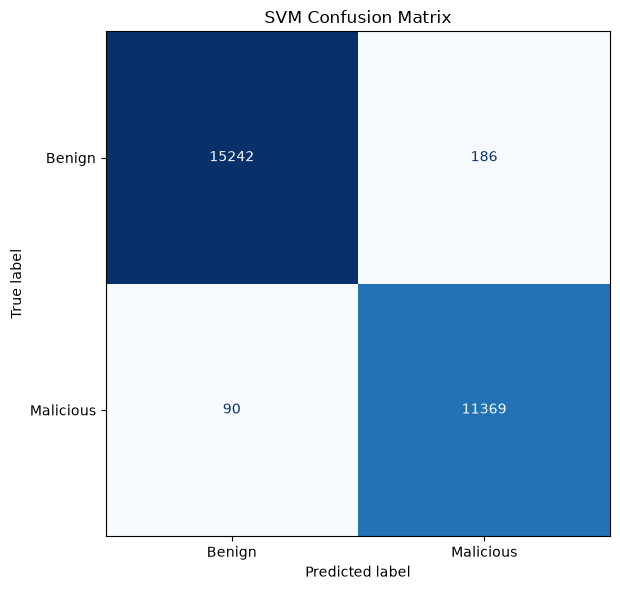

In [12]:
# Calculate and display the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

tn, fp, fn, tp = cm.ravel()

print("Confusion Matrix Values")
print(f"True Negatives  (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives  (TP): {tp}")

fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malicious"]
)
disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)
ax.set_title("SVM Confusion Matrix")
plt.tight_layout()
plt.show()

The confusion matrix provides a breakdown of the model's classification results:

- **True Negatives (14912)**: Benign samples correctly classified as benign.
- **False Positives (516)**: Benign samples incorrectly classified as malicious.
- **False Negatives (215)**: Malicious samples incorrectly classified as benign.
- **True Positives (11244)**: Malicious samples correctly classified as malicious.


### 5.4 ROC Curve Analysis

The ROC curve evaluates the model's ability to distinguish between benign and malicious files at different classification thresholds.

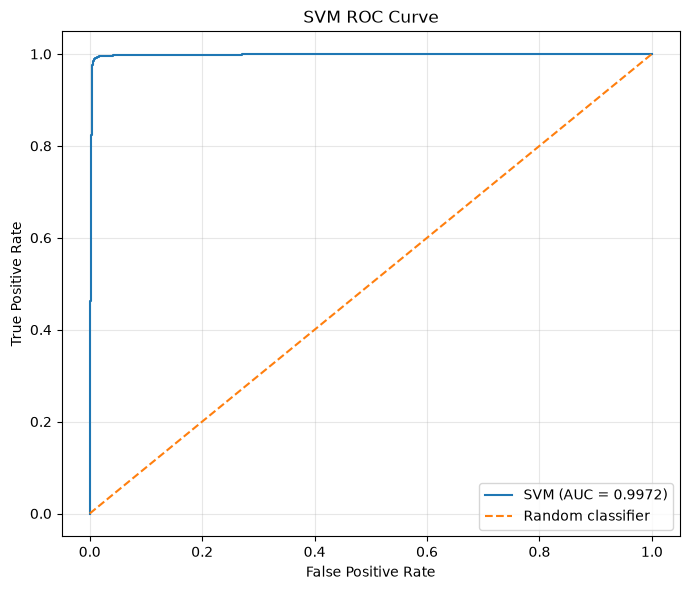

In [14]:
# Calculate ROC curve points from SVM decision scores
fpr, tpr, thresholds = roc_curve(y_test, y_scores, pos_label=1)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"SVM (AUC = {svm_roc_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("SVM ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The SVM model achieves a ROC-AUC score of **99.49%**. This indicates an excellent ability to distinguish between benign and malicious samples.

The ROC curve is close to the upper-left corner, showing a high True Positive Rate and a low False Positive Rate.

## 6. Model Saving



In [16]:
from pathlib import Path
import joblib

# Create the output directory if it does not already exist
MODEL_DIR = Path("../../models/baselines")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "svm_baseline.joblib"

# Save the complete fitted pipeline
joblib.dump(best_svm_model, MODEL_PATH)

print(f"SVM model saved successfully to: {MODEL_PATH}")

SVM model saved successfully to: ..\..\models\baselines\svm_baseline.joblib


## 7. Conclusion

The SVM baseline achieves strong performance on the BODMAS dataset, with **97.28% accuracy**, **96.85% F1-score for the malicious class**, and **99.49% ROC-AUC**.

The model successfully detects most malicious samples while maintaining good performance on benign files. These results make SVM a strong baseline for malware detection.

The next step is to compare its performance with the MLP model using the same evaluation metrics to determine which model is more suitable for this task.